# Alzheimer Drug Target Explorer

# Retrieving Target Information from ChEMBL

### Objective
To collect and explore Alzheimer's-related biological target data using the ChEMBL API.

### Tools Used
Python, Requests, Pandas, Matplotlib, and Jupyter Notebook.

### Methodology
Data was retrieved from the ChEMBL API using the keyword "Alzheimer". The returned 7 records were organized into a Pandas DataFrame. Target types and organisms were explored using bar charts.

### Findings
The dataset contained different target types and records from human, rat, and mouse organisms.

### Conclusion
Established the basic workflow for API data collection, data organization, and visualization.

### Next Step
Retrieve disease–target associations from Open Targets and experimental activity data from ChEMBL.

In [1]:
import requests
import pandas as pd
import json
from pathlib import Path

In [2]:
import requests

url = "https://www.ebi.ac.uk/chembl/api/data/target/search.json"

params = {
    "q": "Alzheimer",
    "limit": 10
}

response = requests.get(url, params=params, timeout=30)

print("Status code:", response.status_code)


Status code: 200


In [3]:
data = response.json()

print(type(data))
print(data.keys())


<class 'dict'>
dict_keys(['page_meta', 'targets'])


## Target records

In [4]:
targets = data.get("targets", [])

print("Number of records:", len(targets))

if targets:
    print(targets[0])


Number of records: 7
{'cross_references': [], 'organism': 'Homo sapiens', 'pref_name': 'Nucleosome-remodeling factor subunit BPTF', 'score': 13.0, 'species_group_flag': False, 'target_chembl_id': 'CHEMBL3085621', 'target_components': [{'accession': 'Q12830', 'component_description': 'Nucleosome-remodeling factor subunit BPTF', 'component_id': 8255, 'component_type': 'PROTEIN', 'relationship': 'SINGLE PROTEIN', 'target_component_synonyms': [{'component_synonym': 'FAC1', 'syn_type': 'GENE_SYMBOL_OTHER'}, {'component_synonym': 'FALZ', 'syn_type': 'GENE_SYMBOL_OTHER'}, {'component_synonym': 'BPTF', 'syn_type': 'GENE_SYMBOL'}, {'component_synonym': 'Nucleosome-remodeling factor subunit BPTF', 'syn_type': 'UNIPROT'}, {'component_synonym': 'Bromodomain and PHD finger-containing transcription factor', 'syn_type': 'UNIPROT'}, {'component_synonym': 'Fetal Alz-50 clone 1 protein', 'syn_type': 'UNIPROT'}, {'component_synonym': 'Fetal Alzheimer antigen', 'syn_type': 'UNIPROT'}], 'target_component_x

In [5]:
import json
from pathlib import Path

output_folder = Path("../data/raw")
output_folder.mkdir(parents=True, exist_ok=True)

with open(
    output_folder / "target_search.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(data, file, indent=2)

print("Data saved successfully!")


Data saved successfully!


In [6]:
for target in targets:
    print("Target Name:", target.get("pref_name"))
    print("Target ID:", target.get("target_chembl_id"))
    print("Target Type:", target.get("target_type"))
    print("-" * 40)

Target Name: Nucleosome-remodeling factor subunit BPTF
Target ID: CHEMBL3085621
Target Type: SINGLE PROTEIN
----------------------------------------
Target Name: Nicastrin
Target ID: CHEMBL3418
Target Type: SINGLE PROTEIN
----------------------------------------
Target Name: Gamma-secretase
Target ID: CHEMBL2094135
Target Type: PROTEIN COMPLEX
----------------------------------------
Target Name: Protein cereblon/Nucleosome-remodeling factor subunit BPTF
Target ID: CHEMBL6195548
Target Type: PROTEIN-PROTEIN INTERACTION
----------------------------------------
Target Name: Amyloid-beta precursor protein
Target ID: CHEMBL3638365
Target Type: SINGLE PROTEIN
----------------------------------------
Target Name: Amyloid-beta precursor protein
Target ID: CHEMBL4523942
Target Type: SINGLE PROTEIN
----------------------------------------
Target Name: Amyloid-beta precursor protein
Target ID: CHEMBL2487
Target Type: SINGLE PROTEIN
----------------------------------------


In [7]:
df = pd.DataFrame(targets)

print(df.shape)
display(df.head())

(7, 9)


,cross_references,organism,pref_name,score,species_group_flag,target_chembl_id,target_components,target_type,tax_id
0,[],Homo sapiens,Nucleosome-remodeling factor subunit BPTF,13.0,False,CHEMBL3085621,"[{'accession': 'Q12830', 'component_descriptio...",SINGLE PROTEIN,9606
1,[],Homo sapiens,Nicastrin,12.0,False,CHEMBL3418,"[{'accession': 'Q92542', 'component_descriptio...",SINGLE PROTEIN,9606
2,[],Homo sapiens,Gamma-secretase,12.0,False,CHEMBL2094135,"[{'accession': 'Q96BI3', 'component_descriptio...",PROTEIN COMPLEX,9606
3,[],Homo sapiens,Protein cereblon/Nucleosome-remodeling factor ...,12.0,False,CHEMBL6195548,"[{'accession': 'Q12830', 'component_descriptio...",PROTEIN-PROTEIN INTERACTION,9606
4,[],Rattus norvegicus,Amyloid-beta precursor protein,9.0,False,CHEMBL3638365,"[{'accession': 'P08592', 'component_descriptio...",SINGLE PROTEIN,10116


In [8]:
print(df.columns)

Index(['cross_references', 'organism', 'pref_name', 'score',
       'species_group_flag', 'target_chembl_id', 'target_components',
       'target_type', 'tax_id'],
      dtype='str')


In [9]:
print(df.columns.tolist())

['cross_references', 'organism', 'pref_name', 'score', 'species_group_flag', 'target_chembl_id', 'target_components', 'target_type', 'tax_id']


In [10]:
target_df = df[
    ["pref_name", "target_chembl_id", "target_type", "organism", "score"]
].copy()

display(target_df)

,pref_name,target_chembl_id,target_type,organism,score
0,Nucleosome-remodeling factor subunit BPTF,CHEMBL3085621,SINGLE PROTEIN,Homo sapiens,13.0
1,Nicastrin,CHEMBL3418,SINGLE PROTEIN,Homo sapiens,12.0
2,Gamma-secretase,CHEMBL2094135,PROTEIN COMPLEX,Homo sapiens,12.0
3,Protein cereblon/Nucleosome-remodeling factor ...,CHEMBL6195548,PROTEIN-PROTEIN INTERACTION,Homo sapiens,12.0
4,Amyloid-beta precursor protein,CHEMBL3638365,SINGLE PROTEIN,Rattus norvegicus,9.0
5,Amyloid-beta precursor protein,CHEMBL4523942,SINGLE PROTEIN,Mus musculus,8.0
6,Amyloid-beta precursor protein,CHEMBL2487,SINGLE PROTEIN,Homo sapiens,7.0


In [11]:
print(target_df.isnull().sum())

pref_name           0
target_chembl_id    0
target_type         0
organism            0
score               0
dtype: int64


## Data Cleaning and Preparation

In [12]:
print("Dataset Information:")
target_df.info()

print("Missing Values:")
print(target_df.isnull().sum())

print("Duplicate Rows:")
print(target_df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   pref_name         7 non-null      str    
 1   target_chembl_id  7 non-null      str    
 2   target_type       7 non-null      str    
 3   organism          7 non-null      str    
 4   score             7 non-null      float64
dtypes: float64(1), str(4)
memory usage: 911.0 bytes
Missing Values:
pref_name           0
target_chembl_id    0
target_type         0
organism            0
score               0
dtype: int64
Duplicate Rows:
0


##  Data Validation and Quality Check

In [13]:
print("Target Types:")
print(target_df["target_type"].value_counts())

print("\nOrganisms:")
print(target_df["organism"].value_counts())

print("\nTarget Names:")
print(target_df["pref_name"].to_list())

Target Types:
target_type
SINGLE PROTEIN                 5
PROTEIN COMPLEX                1
PROTEIN-PROTEIN INTERACTION    1
Name: count, dtype: int64

Organisms:
organism
Homo sapiens         5
Rattus norvegicus    1
Mus musculus         1
Name: count, dtype: int64

Target Names:
['Nucleosome-remodeling factor subunit BPTF', 'Nicastrin', 'Gamma-secretase', 'Protein cereblon/Nucleosome-remodeling factor subunit BPTF', 'Amyloid-beta precursor protein', 'Amyloid-beta precursor protein', 'Amyloid-beta precursor protein']


## Target Distribution and Comparative Analysis

In [14]:
target_counts = target_df["pref_name"].value_counts()

print(target_counts)

pref_name
Amyloid-beta precursor protein                                3
Nucleosome-remodeling factor subunit BPTF                     1
Nicastrin                                                     1
Gamma-secretase                                               1
Protein cereblon/Nucleosome-remodeling factor subunit BPTF    1
Name: count, dtype: int64


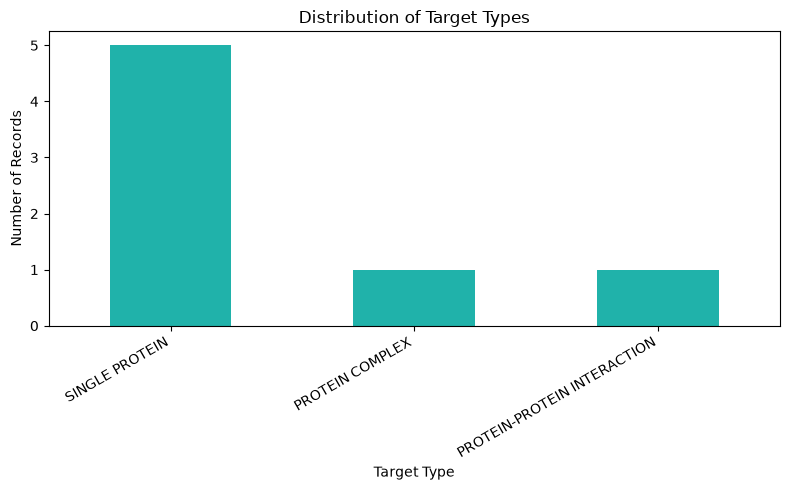

In [15]:
import matplotlib.pyplot as plt

type_counts = target_df["target_type"].value_counts()

type_counts.plot(kind="bar", figsize=(8, 5) , color='#20B2AA')

plt.title("Distribution of Target Types")
plt.xlabel("Target Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

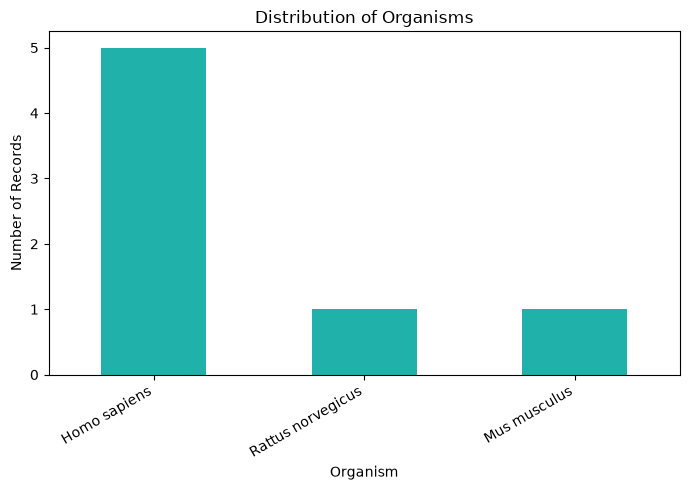

In [16]:
organism_counts = target_df["organism"].value_counts()

organism_counts.plot(kind="bar", figsize=(7, 5) , color='#20B2AA')

plt.title("Distribution of Organisms")
plt.xlabel("Organism")
plt.ylabel("Number of Records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Unique Target Identification

In [17]:
unique_targets = target_df.drop_duplicates(
    subset=["target_chembl_id"]
)

print("Total records:", len(target_df))
print("Unique target IDs:", unique_targets["target_chembl_id"].nunique())

display(
    unique_targets[
        ["pref_name", "target_chembl_id", "target_type", "organism"]
    ]
)

Total records: 7
Unique target IDs: 7


,pref_name,target_chembl_id,target_type,organism
0,Nucleosome-remodeling factor subunit BPTF,CHEMBL3085621,SINGLE PROTEIN,Homo sapiens
1,Nicastrin,CHEMBL3418,SINGLE PROTEIN,Homo sapiens
2,Gamma-secretase,CHEMBL2094135,PROTEIN COMPLEX,Homo sapiens
3,Protein cereblon/Nucleosome-remodeling factor ...,CHEMBL6195548,PROTEIN-PROTEIN INTERACTION,Homo sapiens
4,Amyloid-beta precursor protein,CHEMBL3638365,SINGLE PROTEIN,Rattus norvegicus
5,Amyloid-beta precursor protein,CHEMBL4523942,SINGLE PROTEIN,Mus musculus
6,Amyloid-beta precursor protein,CHEMBL2487,SINGLE PROTEIN,Homo sapiens


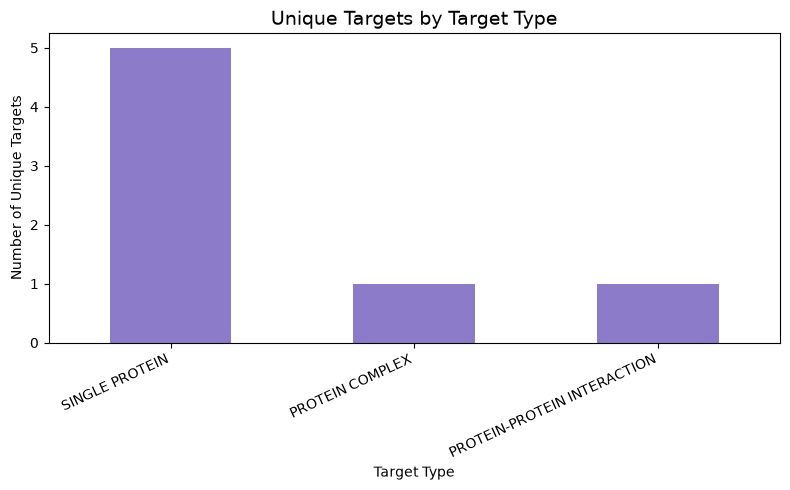

In [18]:
unique_counts = unique_targets["target_type"].value_counts()

unique_counts.plot(
    kind="bar",
    figsize=(8, 5),
    color= "#8B7BC8"
)

plt.title("Unique Targets by Target Type", fontsize=14)
plt.xlabel("Target Type")
plt.ylabel("Number of Unique Targets")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Disease–Target Evidence and Validation
### Objectives
- Retrieve Alzheimer’s disease-associated targets from Open Targets.
- Collect compound bioactivity records from ChEMBL.
- Perform initial data quality checks.
- Inspect assay descriptions and activity measurements.

### Results
- Disease ID: MONDO_0004975
- Associated target records reported by API: 13,006
- Targets retrieved for initial inspection: 10
- ChEMBL activity records retrieved: 20
- Duplicate activity rows: 0
- Missing pChEMBL values: 11

### Initial Findings
APP had the highest association score among the 10 retrieved Open Targets records. In the retrieved ChEMBL records, CHEMBL55380 had the lowest Ki value (0.9 nM) among the 11 Ki records measured in nM.

### Limitations
The analysis uses an initial sample of targets and activity records. Different assay types and measurements cannot be directly combined. Target and assay relationships require further validation. Experimental activity does not prove clinical effectiveness against Alzheimer’s disease.

### Next Steps
- Validate target identifiers and assay context.
- Improve data cleaning and analysis.
- Create meaningful visualizations.
- Compare disease association evidence with suitable experimental compound data.

In [19]:
import requests

url = "https://api.platform.opentargets.org/api/v4/graphql"

print(url)

https://api.platform.opentargets.org/api/v4/graphql


In [20]:
import requests

url = "https://api.platform.opentargets.org/api/v4/graphql"

query = """
query {
  search(
    queryString: "Alzheimer disease"
    entityNames: ["disease"]
    page: {index: 0, size: 10}
  ) {
    hits {
      id
      name
      entity
    }
  }
}
"""

response = requests.post(
    url,
    json={"query": query},
    timeout=30
)

print("Status:", response.status_code)
print(response.text[:2000])

Status: 200
{"data":{"search":{"hits":[{"id":"MONDO_0004975","name":"Alzheimer disease","entity":"disease"},{"id":"MONDO_0100087","name":"familial Alzheimer disease","entity":"disease"},{"id":"MONDO_0015140","name":"early-onset autosomal dominant Alzheimer disease","entity":"disease"},{"id":"EFO_1001870","name":"late-onset Alzheimers disease","entity":"disease"},{"id":"MONDO_0011913","name":"Alzheimer disease 3","entity":"disease"},{"id":"EFO_0009268","name":"family history of Alzheimer’s disease","entity":"disease"},{"id":"EFO_0006514","name":"Alzheimer's disease biomarker measurement","entity":"disease"},{"id":"EFO_0022957","name":"early-onset Alzheimers disease","entity":"disease"},{"id":"MONDO_0007088","name":"Alzheimer disease type 1","entity":"disease"},{"id":"MONDO_0014265","name":"Alzheimer disease 18","entity":"disease"}]}}}


In [21]:
result = response.json()

print(result.keys())
print(result.get("errors", "No errors found"))

dict_keys(['data'])
No errors found


In [22]:
hits = result.get("data", {}).get("search", {}).get("hits", [])

print("Total results:", len(hits))

for hit in hits:
    print("Disease:", hit.get("name"))
    print("ID:", hit.get("id"))
    print("Entity:", hit.get("entity"))
    print("-" * 40)

Total results: 10
Disease: Alzheimer disease
ID: MONDO_0004975
Entity: disease
----------------------------------------
Disease: familial Alzheimer disease
ID: MONDO_0100087
Entity: disease
----------------------------------------
Disease: early-onset autosomal dominant Alzheimer disease
ID: MONDO_0015140
Entity: disease
----------------------------------------
Disease: late-onset Alzheimers disease
ID: EFO_1001870
Entity: disease
----------------------------------------
Disease: Alzheimer disease 3
ID: MONDO_0011913
Entity: disease
----------------------------------------
Disease: family history of Alzheimer’s disease
ID: EFO_0009268
Entity: disease
----------------------------------------
Disease: Alzheimer's disease biomarker measurement
ID: EFO_0006514
Entity: disease
----------------------------------------
Disease: early-onset Alzheimers disease
ID: EFO_0022957
Entity: disease
----------------------------------------
Disease: Alzheimer disease type 1
ID: MONDO_0007088
Entity: dis

In [23]:
query = """
query {
  disease(efoId: "MONDO_0004975") {
    id
    name
    associatedTargets(page: {index: 0, size: 10}) {
      count
      rows {
        score
        target {
          id
          approvedSymbol
          approvedName
        }
      }
    }
  }
}
"""

response_targets = requests.post(
    url,
    json={"query": query},
    timeout=30
)

print("Status:", response_targets.status_code)
print(response_targets.text[:2000])



Status: 200
{"data":{"disease":{"id":"MONDO_0004975","name":"Alzheimer disease","associatedTargets":{"count":13006,"rows":[{"score":0.8743017509514485,"target":{"id":"ENSG00000142192","approvedSymbol":"APP","approvedName":"amyloid beta precursor protein"}},{"score":0.8678833473880588,"target":{"id":"ENSG00000080815","approvedSymbol":"PSEN1","approvedName":"presenilin 1"}},{"score":0.818963537542181,"target":{"id":"ENSG00000143801","approvedSymbol":"PSEN2","approvedName":"presenilin 2"}},{"score":0.7882988926262811,"target":{"id":"ENSG00000130203","approvedSymbol":"APOE","approvedName":"apolipoprotein E"}},{"score":0.740796098932307,"target":{"id":"ENSG00000064687","approvedSymbol":"ABCA7","approvedName":"ATP binding cassette subfamily A member 7"}},{"score":0.7146776827220991,"target":{"id":"ENSG00000137642","approvedSymbol":"SORL1","approvedName":"sortilin related receptor 1"}},{"score":0.7049058021654173,"target":{"id":"ENSG00000176884","approvedSymbol":"GRIN1","approvedName":"glutam

In [24]:
result_targets = response_targets.json()

print("Errors:", result_targets.get("errors", "No errors"))

disease_data = result_targets.get("data", {}).get("disease", {})

target_rows = disease_data.get("associatedTargets", {}).get("rows", [])

print("Total associated targets available:",
      disease_data.get("associatedTargets", {}).get("count"))

print("Targets retrieved:", len(target_rows))


Errors: No errors
Total associated targets available: 13006
Targets retrieved: 10


In [25]:
import pandas as pd

target_data = []

for row in target_rows:
    target = row.get("target", {})

    target_data.append({
        "Target ID": target.get("id"),
        "Gene Symbol": target.get("approvedSymbol"),
        "Target Name": target.get("approvedName"),
        "Association Score": row.get("score")
    })

targets_df = pd.DataFrame(target_data)

display(targets_df)


,Target ID,Gene Symbol,Target Name,Association Score
0,ENSG00000142192,APP,amyloid beta precursor protein,0.874302
1,ENSG00000080815,PSEN1,presenilin 1,0.867883
2,ENSG00000143801,PSEN2,presenilin 2,0.818964
3,ENSG00000130203,APOE,apolipoprotein E,0.788299
4,ENSG00000064687,ABCA7,ATP binding cassette subfamily A member 7,0.740796
5,ENSG00000137642,SORL1,sortilin related receptor 1,0.714678
6,ENSG00000176884,GRIN1,glutamate ionotropic receptor NMDA type subunit 1,0.704906
7,ENSG00000137845,ADAM10,ADAM metallopeptidase domain 10,0.687052
8,ENSG00000164885,CDK5,cyclin dependent kinase 5,0.680228
9,ENSG00000116032,GRIN3B,glutamate ionotropic receptor NMDA type subuni...,0.677158


In [26]:

print("Rows:", targets_df.shape[0])
print("Columns:", targets_df.shape[1])

print("\nMissing values:")
print(targets_df.isnull().sum())

print("\nDuplicate target IDs:")
print(targets_df["Target ID"].duplicated().sum())

print("\nScore range:")
print(targets_df["Association Score"].min(),
      "to",
      targets_df["Association Score"].max())


Rows: 10
Columns: 4

Missing values:
Target ID            0
Gene Symbol          0
Target Name          0
Association Score    0
dtype: int64

Duplicate target IDs:
0

Score range:
0.6771580875817478 to 0.8743017509514485


In [27]:

print("Total ChEMBL target records:", len(target_df))

display(
    target_df[
        ["pref_name", "target_chembl_id", "target_type", "organism"]
    ]
)


Total ChEMBL target records: 7


,pref_name,target_chembl_id,target_type,organism
0,Nucleosome-remodeling factor subunit BPTF,CHEMBL3085621,SINGLE PROTEIN,Homo sapiens
1,Nicastrin,CHEMBL3418,SINGLE PROTEIN,Homo sapiens
2,Gamma-secretase,CHEMBL2094135,PROTEIN COMPLEX,Homo sapiens
3,Protein cereblon/Nucleosome-remodeling factor ...,CHEMBL6195548,PROTEIN-PROTEIN INTERACTION,Homo sapiens
4,Amyloid-beta precursor protein,CHEMBL3638365,SINGLE PROTEIN,Rattus norvegicus
5,Amyloid-beta precursor protein,CHEMBL4523942,SINGLE PROTEIN,Mus musculus
6,Amyloid-beta precursor protein,CHEMBL2487,SINGLE PROTEIN,Homo sapiens


In [28]:

human_app = target_df[
    (target_df["pref_name"] == "Amyloid-beta precursor protein") &
    (target_df["organism"] == "Homo sapiens")
]

display(
    human_app[
        ["pref_name", "target_chembl_id", "organism"]
    ]
)


,pref_name,target_chembl_id,organism
6,Amyloid-beta precursor protein,CHEMBL2487,Homo sapiens


In [29]:

app_target_id = "CHEMBL2487"

activity_url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

activity_params = {
    "target_chembl_id": app_target_id,
    "limit": 20
}

activity_response = requests.get(
    activity_url,
    params=activity_params,
    timeout=30
)

print("Status:", activity_response.status_code)
print(activity_response.text[:1000])


Status: 200
{"activities": [{"action_type": null, "activity_comment": null, "activity_id": 72652, "activity_properties": [], "assay_chembl_id": "CHEMBL649398", "assay_description": "Inhibition constant against [125I]-7 (TZDM) binding to Amyloid beta 1-40 aggregates", "assay_type": "B", "assay_variant_accession": null, "assay_variant_mutation": null, "bao_endpoint": "BAO_0000192", "bao_format": "BAO_0000357", "bao_label": "single protein format", "canonical_smiles": "CN(C)c1ccc(-c2cn3cc(Br)ccc3n2)cc1", "data_validity_comment": null, "data_validity_description": null, "document_chembl_id": "CHEMBL1145100", "document_journal": "J Med Chem", "document_year": 2003, "ligand_efficiency": {"bei": "25.26", "le": "0.57", "lle": "4.16", "sei": "38.89"}, "modality": null, "molecule_chembl_id": "CHEMBL81260", "molecule_pref_name": null, "parent_molecule_chembl_id": "CHEMBL81260", "pchembl_value": "7.99", "potential_duplicate": 0, "qudt_units": "http://www.openphacts.org/units/Nanomolar", "record_id

In [30]:

activity_data = activity_response.json()

activities = activity_data.get("activities", [])

print("Activity records retrieved:", len(activities))

activity_df = pd.DataFrame(activities)

columns_to_keep = [
    "molecule_chembl_id",
    "target_chembl_id",
    "assay_description",
    "assay_type",
    "standard_type",
    "standard_value",
    "standard_units",
    "pchembl_value",
    "document_year"
]

activity_df = activity_df[
    [col for col in columns_to_keep if col in activity_df.columns]
].copy()

display(activity_df.head(10))


Activity records retrieved: 20


,molecule_chembl_id,target_chembl_id,assay_description,assay_type,standard_type,standard_value,standard_units,pchembl_value,document_year
0,CHEMBL81260,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,10.3,nM,7.99,2003
1,CHEMBL55380,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,0.9,nM,9.05,2003
2,CHEMBL78410,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,2000.0,nM,NaN,2003
3,CHEMBL81685,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,1000.0,nM,NaN,2003
4,CHEMBL78621,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,242.0,nM,6.62,2003
5,CHEMBL312622,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,2000.0,nM,NaN,2003
6,CHEMBL310444,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,2000.0,nM,NaN,2003
7,CHEMBL78765,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,638.0,nM,6.20,2003
8,CHEMBL309920,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,339.0,nM,6.47,2003
9,CHEMBL78012,CHEMBL2487,Inhibition constant against [125I]-7 (TZDM) bi...,B,Ki,15.0,nM,7.82,2003


In [31]:

print("Total activity records:", len(activity_df))

print("\nMissing values:")
print(activity_df.isnull().sum())

print("\nDuplicate rows:", activity_df.duplicated().sum())

print("\nActivity measurement types:")
print(activity_df["standard_type"].value_counts(dropna=False))

print("\nActivity units:")
print(activity_df["standard_units"].value_counts(dropna=False))

print("\nPublication years:")
print(activity_df["document_year"].value_counts(dropna=False))


Total activity records: 20

Missing values:
molecule_chembl_id     0
target_chembl_id       0
assay_description      0
assay_type             0
standard_type          0
standard_value         0
standard_units         0
pchembl_value         11
document_year          0
dtype: int64

Duplicate rows: 0

Activity measurement types:
standard_type
Ki             11
Inhibition      4
IC50            3
Stimulation     2
Name: count, dtype: int64

Activity units:
standard_units
nM    14
%      6
Name: count, dtype: int64

Publication years:
document_year
2003    11
2000     9
Name: count, dtype: int64


In [32]:

valid_ki = activity_df[
    (activity_df["standard_type"] == "Ki") &
    (activity_df["standard_units"] == "nM")
].copy()

valid_ki["standard_value"] = pd.to_numeric(
    valid_ki["standard_value"],
    errors="coerce"
)

valid_ki = valid_ki.dropna(subset=["standard_value"])

valid_ki = valid_ki.sort_values(
    by="standard_value",
    ascending=True
)

display(
    valid_ki[
        [
            "molecule_chembl_id",
            "standard_value",
            "standard_units",
            "pchembl_value",
            "document_year"
        ]
    ]
)

print("Valid Ki records:", len(valid_ki))


,molecule_chembl_id,standard_value,standard_units,pchembl_value,document_year
1,CHEMBL55380,0.9,nM,9.05,2003
0,CHEMBL81260,10.3,nM,7.99,2003
9,CHEMBL78012,15.0,nM,7.82,2003
4,CHEMBL78621,242.0,nM,6.62,2003
8,CHEMBL309920,339.0,nM,6.47,2003
7,CHEMBL78765,638.0,nM,6.20,2003
3,CHEMBL81685,1000.0,nM,NaN,2003
2,CHEMBL78410,2000.0,nM,NaN,2003
6,CHEMBL310444,2000.0,nM,NaN,2003
5,CHEMBL312622,2000.0,nM,NaN,2003


Valid Ki records: 11


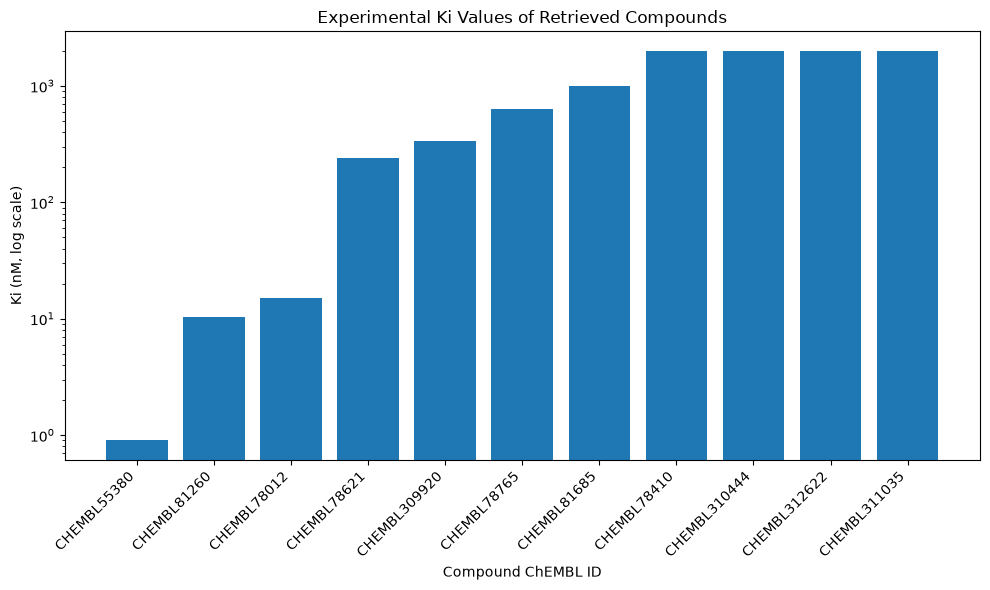

In [33]:

import matplotlib.pyplot as plt

plot_df = valid_ki.dropna(
    subset=["standard_value", "molecule_chembl_id"]
).copy()

plt.figure(figsize=(10, 6))

plt.bar(
    plot_df["molecule_chembl_id"],
    plot_df["standard_value"]
)

plt.yscale("log")
plt.xlabel("Compound ChEMBL ID")
plt.ylabel("Ki (nM, log scale)")
plt.title("Experimental Ki Values of Retrieved Compounds")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [34]:

print("Target ID:", app_target_id)

print("\nAssay descriptions:")
for description in activity_df["assay_description"].dropna().unique():
    print("-", description)

print("\nAssay types:")
print(activity_df["assay_type"].value_counts(dropna=False))

print("\nMeasurement types:")
print(activity_df["standard_type"].value_counts(dropna=False))


Target ID: CHEMBL2487

Assay descriptions:
- Inhibition constant against [125I]-7 (TZDM) binding to Amyloid beta 1-40 aggregates
- Inhibition of A-beta-42 production by inhibiting Gamma-secretase proteolytic pathway in HEK293 cell stably transfected with a double mutant form of human APP(K595N/M596L), at 2.5 uM concentration
- Inhibition of A-beta-42 production by inhibiting Gamma-secretase proteolytic pathway in HEK293 cell stably transfected with a double mutant form of human APP(K595N/M596L)
- Observed stimulation of the production of soluble beta-amyloid precursor protein

Assay types:
assay_type
B    18
F     2
Name: count, dtype: int64

Measurement types:
standard_type
Ki             11
Inhibition      4
IC50            3
Stimulation     2
Name: count, dtype: int64


# Drug–Target Evidence Analysis

## 1. Target Identification and Validation

The aim of this stage is to examine the retrieved target records, verify their identifiers, and prepare for the analysis of experimental compound–target activity data.

In [35]:

print("Total target records:", len(target_df))

print("Unique target IDs:",
      target_df["target_chembl_id"].nunique())

display(
    target_df[
        ["pref_name", "target_chembl_id",
         "target_type", "organism"]
    ].sort_values("pref_name")
)

Total target records: 7
Unique target IDs: 7


,pref_name,target_chembl_id,target_type,organism
4,Amyloid-beta precursor protein,CHEMBL3638365,SINGLE PROTEIN,Rattus norvegicus
5,Amyloid-beta precursor protein,CHEMBL4523942,SINGLE PROTEIN,Mus musculus
6,Amyloid-beta precursor protein,CHEMBL2487,SINGLE PROTEIN,Homo sapiens
2,Gamma-secretase,CHEMBL2094135,PROTEIN COMPLEX,Homo sapiens
1,Nicastrin,CHEMBL3418,SINGLE PROTEIN,Homo sapiens
0,Nucleosome-remodeling factor subunit BPTF,CHEMBL3085621,SINGLE PROTEIN,Homo sapiens
3,Protein cereblon/Nucleosome-remodeling factor ...,CHEMBL6195548,PROTEIN-PROTEIN INTERACTION,Homo sapiens


In [36]:
import requests
import pandas as pd

target_id = "CHEMBL2487"

url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

params = {
    "target_chembl_id": target_id,
    "limit": 100
}

response = requests.get(url, params=params, timeout=30)

print("Status code:", response.status_code)

activity_data = response.json()
activities = activity_data.get("activities", [])

print("Activity records retrieved:", len(activities))

Status code: 200
Activity records retrieved: 100


In [37]:
activity_df = pd.DataFrame(activities)

print("Dataset shape:", activity_df.shape)
print(activity_df.columns.tolist())

Dataset shape: (100, 47)
['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 'upper_value', 'value']


In [38]:
columns_to_check = [
    "molecule_chembl_id",
    "target_chembl_id",
    "assay_chembl_id",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pchembl_value",
    "target_organism"
]

available_columns = [
    col for col in columns_to_check
    if col in activity_df.columns
]

display(activity_df[available_columns].head(10))

,molecule_chembl_id,target_chembl_id,assay_chembl_id,standard_type,standard_relation,standard_value,standard_units,pchembl_value,target_organism
0,CHEMBL81260,CHEMBL2487,CHEMBL649398,Ki,=,10.3,nM,7.99,Homo sapiens
1,CHEMBL55380,CHEMBL2487,CHEMBL649398,Ki,=,0.9,nM,9.05,Homo sapiens
2,CHEMBL78410,CHEMBL2487,CHEMBL649398,Ki,>,2000.0,nM,NaN,Homo sapiens
3,CHEMBL81685,CHEMBL2487,CHEMBL649398,Ki,>,1000.0,nM,NaN,Homo sapiens
4,CHEMBL78621,CHEMBL2487,CHEMBL649398,Ki,=,242.0,nM,6.62,Homo sapiens
5,CHEMBL312622,CHEMBL2487,CHEMBL649398,Ki,>,2000.0,nM,NaN,Homo sapiens
6,CHEMBL310444,CHEMBL2487,CHEMBL649398,Ki,>,2000.0,nM,NaN,Homo sapiens
7,CHEMBL78765,CHEMBL2487,CHEMBL649398,Ki,=,638.0,nM,6.20,Homo sapiens
8,CHEMBL309920,CHEMBL2487,CHEMBL649398,Ki,=,339.0,nM,6.47,Homo sapiens
9,CHEMBL78012,CHEMBL2487,CHEMBL649398,Ki,=,15.0,nM,7.82,Homo sapiens


## 2. Experimental Activity Data Quality Assessment

The activity records retrieved from ChEMBL contain compound identifiers, target identifiers, assay identifiers, activity types, measured values, units, and pChEMBL values where available.

The dataset will be checked for missing values, duplicate records, and the distribution of activity measurement types before further analysis.

In [39]:
print("Dataset shape:", activity_df.shape)

print("\nMissing values:")
print(activity_df[available_columns].isnull().sum())


print("\nDuplicate rows:")

print(activity_df[available_columns].duplicated().sum())

print("\nActivity measurement types:")
print(activity_df["standard_type"].value_counts(dropna=False))

print("\nMeasurement units:")
print(activity_df["standard_units"].value_counts(dropna=False))

print("\nRelation types:")
print(activity_df["standard_relation"].value_counts(dropna=False))

Dataset shape: (100, 47)

Missing values:
molecule_chembl_id     0
target_chembl_id       0
assay_chembl_id        0
standard_type          0
standard_relation      4
standard_value         4
standard_units         0
pchembl_value         39
target_organism        0
dtype: int64

Duplicate rows:
2

Activity measurement types:
standard_type
Ki             64
EC50           17
Inhibition      9
IC50            5
Stimulation     5
Name: count, dtype: int64

Measurement units:
standard_units
nM    86
%     14
Name: count, dtype: int64

Relation types:
standard_relation
=      75
>      20
NaN     4
<       1
Name: count, dtype: int64


In [40]:

# Select the columns needed for activity analysis
activity_clean = activity_df[
    [
        "molecule_chembl_id",
        "target_chembl_id",
        "assay_chembl_id",
        "standard_type",
        "standard_relation",
        "standard_value",
        "standard_units",
        "pchembl_value",
        "target_organism"
    ]
].copy()

# Convert activity values to numeric
activity_clean["standard_value"] = pd.to_numeric(
    activity_clean["standard_value"], errors="coerce"
)

activity_clean["pchembl_value"] = pd.to_numeric(
    activity_clean["pchembl_value"], errors="coerce"
)

# Summarize the different activity measurements
activity_summary = (
    activity_clean
    .groupby(["standard_type", "standard_units"], dropna=False)
    .agg(
        record_count=("molecule_chembl_id", "size"),
        unique_compounds=("molecule_chembl_id", "nunique"),
        missing_values=("standard_value", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(activity_summary)


,standard_type,standard_units,record_count,unique_compounds,missing_values
0,EC50,nM,17,8,4
1,IC50,nM,5,5,0
2,Inhibition,%,9,9,0
3,Ki,nM,64,39,0
4,Stimulation,%,5,5,0


In [41]:

# Keep only exact Ki measurements reported in nM
ki_df = activity_clean[
    (activity_clean["standard_type"] == "Ki") &
    (activity_clean["standard_units"] == "nM") &
    (activity_clean["standard_relation"] == "=") &
    (activity_clean["standard_value"].notna())
].copy()

# Sort from lowest Ki value to highest
ki_df = ki_df.sort_values("standard_value", ascending=True)

print("Exact Ki records:", len(ki_df))
print("Unique compounds:", ki_df["molecule_chembl_id"].nunique())

display(
    ki_df[
        [
            "molecule_chembl_id",
            "standard_value",
            "standard_units",
            "pchembl_value",
            "assay_chembl_id"
        ]
    ].head(10)
)


Exact Ki records: 44
Unique compounds: 33


,molecule_chembl_id,standard_value,standard_units,pchembl_value,assay_chembl_id
34,CHEMBL74704,0.11,nM,9.96,CHEMBL649530
29,CHEMBL76112,0.13,nM,9.89,CHEMBL649530
32,CHEMBL300172,0.14,nM,9.85,CHEMBL649530
47,CHEMBL300172,0.14,nM,9.85,CHEMBL649529
43,CHEMBL292910,0.17,nM,9.77,CHEMBL649529
31,CHEMBL305634,0.19,nM,9.72,CHEMBL649530
30,CHEMBL74348,0.27,nM,9.57,CHEMBL649530
49,CHEMBL300172,0.40,nM,9.40,CHEMBL649527
54,CHEMBL55401,0.80,nM,9.10,CHEMBL649528
45,CHEMBL292910,0.80,nM,9.10,CHEMBL649529


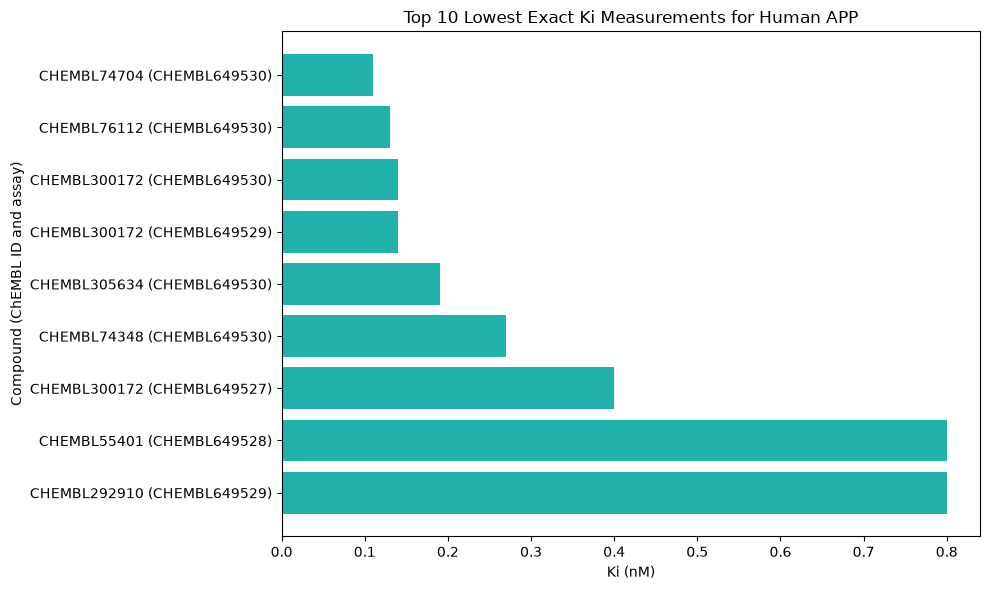

In [42]:

import matplotlib.pyplot as plt

top_ki = ki_df.nsmallest(10, "standard_value").copy()

# Include assay ID in labels because a compound may have
# multiple measurements from different assays
top_ki["label"] = (
    top_ki["molecule_chembl_id"]
    + " ("
    + top_ki["assay_chembl_id"]
    + ")"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_ki["label"].iloc[::-1],
    top_ki["standard_value"].iloc[::-1],
    color="#20B2AA"
)

plt.xlabel("Ki (nM)")
plt.ylabel("Compound (ChEMBL ID and assay)")
plt.title("Top 10 Lowest Exact Ki Measurements for Human APP")
plt.tight_layout()
plt.show()


In [43]:

import requests
import pandas as pd

assay_ids = [
    "CHEMBL649530",
    "CHEMBL649529",
    "CHEMBL649527",
    "CHEMBL649528"
]

assay_details = []

for assay_id in assay_ids:
    url = f"https://www.ebi.ac.uk/chembl/api/data/assay/{assay_id}.json"
    response = requests.get(url, timeout=30)

    if response.status_code == 200:
        assay = response.json()

        assay_details.append({
            "assay_id": assay_id,
            "description": assay.get("description"),
            "assay_type": assay.get("assay_type"),
            "organism": assay.get("assay_organism"),
            "document_id": assay.get("document_chembl_id")
        })
    else:
        print("Could not retrieve:", assay_id)

assay_df = pd.DataFrame(assay_details)
display(assay_df)


,assay_id,description,assay_type,organism,document_id
0,CHEMBL649530,Inhibitory activity against binding of [125I]I...,B,NaN,CHEMBL1134523
1,CHEMBL649529,Inhibition constant for aggregates of amyloid ...,B,Homo sapiens,CHEMBL1134439
2,CHEMBL649527,Inhibition constant of compound on ligand bind...,B,NaN,CHEMBL1134439
3,CHEMBL649528,Inhibition constant for amyloid beta compared ...,B,Homo sapiens,CHEMBL1134439


In [44]:

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

display(
    assay_df[
        ["assay_id", "description", "assay_type", "organism", "document_id"]
    ].to_string(index=False)
)


'    assay_id                                                                                                               description assay_type     organism   document_id\nCHEMBL649530                                                Inhibitory activity against binding of [125I]IMSB to amyloid beta in brain          B          NaN CHEMBL1134523\nCHEMBL649529                                                 Inhibition constant for aggregates of amyloid beta compared to [125I]IMSB          B Homo sapiens CHEMBL1134439\nCHEMBL649527 Inhibition constant of compound on ligand binding to aggregates of Amyloid beta was measured by comparing with [125I]IMSB          B          NaN CHEMBL1134439\nCHEMBL649528                                                               Inhibition constant for amyloid beta compared to [125I]TZDM          B Homo sapiens CHEMBL1134439'

In [45]:

for doc_id in assay_df["document_id"].dropna().unique():
    url = f"https://www.ebi.ac.uk/chembl/api/data/document/{doc_id}.json"
    response = requests.get(url, timeout=30)

    print("\nDocument ID:", doc_id)

    if response.status_code == 200:
        doc = response.json()
        print("Title:", doc.get("title"))
        print("Journal:", doc.get("journal"))
        print("Year:", doc.get("year"))
        print("DOI:", doc.get("doi"))
    else:
        print("Document details unavailable")



Document ID: CHEMBL1134523
Title: Isomerization of (Z,Z) to (E,E)1-bromo-2,5-bis-(3-hydroxycarbonyl-4-hydroxy)styrylbenzene in strong base: probes for amyloid plaques in the brain.
Journal: J Med Chem
Year: 2001
DOI: 10.1021/jm010161t

Document ID: CHEMBL1134439
Title: Radioiodinated styrylbenzenes and thioflavins as probes for amyloid aggregates.
Journal: J Med Chem
Year: 2001
DOI: 10.1021/jm010045q


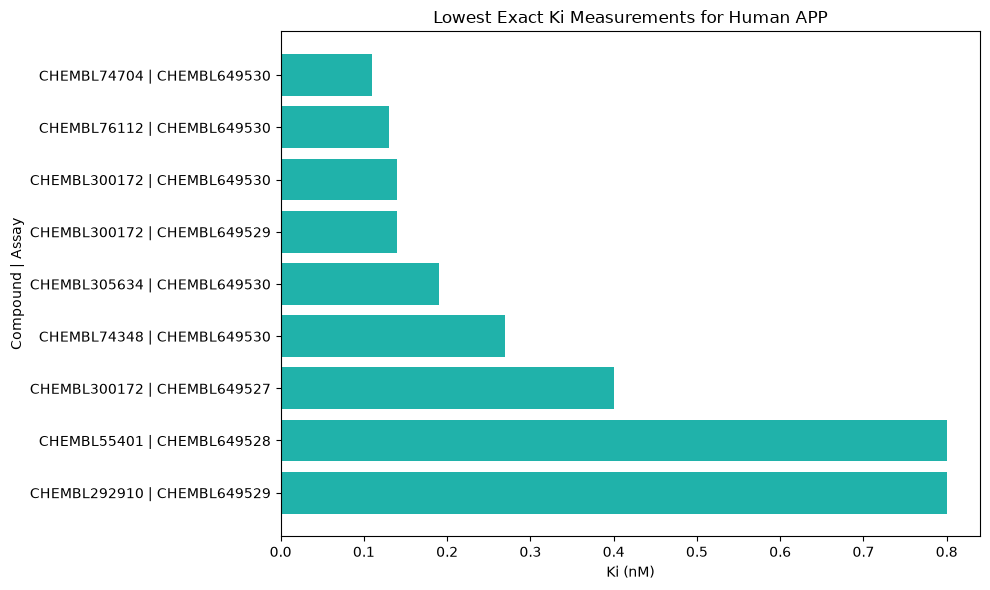

In [46]:

import matplotlib.pyplot as plt

top_ki = ki_df.nsmallest(10, "standard_value").copy()

top_ki["label"] = (
    top_ki["molecule_chembl_id"]
    + " | "
    + top_ki["assay_chembl_id"]
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_ki["label"].iloc[::-1],
    top_ki["standard_value"].iloc[::-1],
    color="#20B2AA"
)

plt.xlabel("Ki (nM)")
plt.ylabel("Compound | Assay")
plt.title("Lowest Exact Ki Measurements for Human APP")
plt.tight_layout()
plt.savefig("top_ki_compounds.png", dpi=300, bbox_inches="tight")
plt.show()


#  Alzheimer’s Disease Analysis

## Data Collection

### Research Findings

In [47]:

import requests
import pandas as pd

url = "https://api.platform.opentargets.org/api/v4/graphql"

query = """
query SearchDisease($queryString: String!) {
    search(
        queryString: $queryString,
        entityNames: ["disease"],
        page: {index: 0, size: 10}
    ) {
        hits {
            id
            name
            entity
        }
    }
}
"""

variables = {
    "queryString": "Alzheimer disease"
}

response = requests.post(
    url,
    json={"query": query, "variables": variables},
    timeout=30
)

print("Status code:", response.status_code)

result = response.json()

if response.status_code == 200 and "errors" not in result:
    hits = result.get("data", {}).get("search", {}).get("hits", [])
    disease_search_df = pd.DataFrame(hits)
    display(disease_search_df)
else:
    print(result)



Status code: 200


,id,name,entity
0,MONDO_0004975,Alzheimer disease,disease
1,MONDO_0100087,familial Alzheimer disease,disease
2,MONDO_0015140,early-onset autosomal dominant Alzheimer disease,disease
3,EFO_1001870,late-onset Alzheimers disease,disease
4,MONDO_0011913,Alzheimer disease 3,disease
5,EFO_0009268,family history of Alzheimer’s disease,disease
6,EFO_0006514,Alzheimer's disease biomarker measurement,disease
7,EFO_0022957,early-onset Alzheimers disease,disease
8,MONDO_0007088,Alzheimer disease type 1,disease
9,MONDO_0014265,Alzheimer disease 18,disease


In [48]:

import requests
import pandas as pd

url = "https://api.platform.opentargets.org/api/v4/graphql"

query = """
query DiseaseTargets($diseaseId: String!) {
    disease(efoId: $diseaseId) {
        id
        name
        associatedTargets(page: {index: 0, size: 10}) {
            count
            rows {
                score
                target {
                    id
                    approvedSymbol
                    approvedName
                }
            }
        }
    }
}
"""

variables = {
    "diseaseId": "MONDO_0004975"
}

response = requests.post(
    url,
    json={"query": query, "variables": variables},
    timeout=30
)

print("Status code:", response.status_code)

result = response.json()

if response.status_code == 200 and "errors" not in result:
    disease = result["data"]["disease"]

    print("Disease:", disease["name"])
    print("Disease ID:", disease["id"])

    target_data = disease["associatedTargets"]
    print("Total associated targets:", target_data["count"])

    rows = []

    for item in target_data["rows"]:
        target = item["target"]

        rows.append({
            "target_id": target["id"],
            "gene_symbol": target["approvedSymbol"],
            "target_name": target["approvedName"],
            "association_score": item["score"]
        })

    target_df = pd.DataFrame(rows)
    display(target_df)

else:
    print("API response:")
    print(result)


Status code: 200
Disease: Alzheimer disease
Disease ID: MONDO_0004975
Total associated targets: 13006


,target_id,gene_symbol,target_name,association_score
0,ENSG00000142192,APP,amyloid beta precursor protein,0.874302
1,ENSG00000080815,PSEN1,presenilin 1,0.867883
2,ENSG00000143801,PSEN2,presenilin 2,0.818964
3,ENSG00000130203,APOE,apolipoprotein E,0.788299
4,ENSG00000064687,ABCA7,ATP binding cassette subfamily A member 7,0.740796
5,ENSG00000137642,SORL1,sortilin related receptor 1,0.714678
6,ENSG00000176884,GRIN1,glutamate ionotropic receptor NMDA type subunit 1,0.704906
7,ENSG00000137845,ADAM10,ADAM metallopeptidase domain 10,0.687052
8,ENSG00000164885,CDK5,cyclin dependent kinase 5,0.680228
9,ENSG00000116032,GRIN3B,glutamate ionotropic receptor NMDA type subunit 3B,0.677158


In [49]:

# Save Open Targets results
target_df.to_csv("alzheimer_associated_targets.csv", index=False)

print("Target dataset saved successfully!")
print("Dataset shape:", target_df.shape)
display(target_df.head())



Target dataset saved successfully!
Dataset shape: (10, 4)


,target_id,gene_symbol,target_name,association_score
0,ENSG00000142192,APP,amyloid beta precursor protein,0.874302
1,ENSG00000080815,PSEN1,presenilin 1,0.867883
2,ENSG00000143801,PSEN2,presenilin 2,0.818964
3,ENSG00000130203,APOE,apolipoprotein E,0.788299
4,ENSG00000064687,ABCA7,ATP binding cassette subfamily A member 7,0.740796


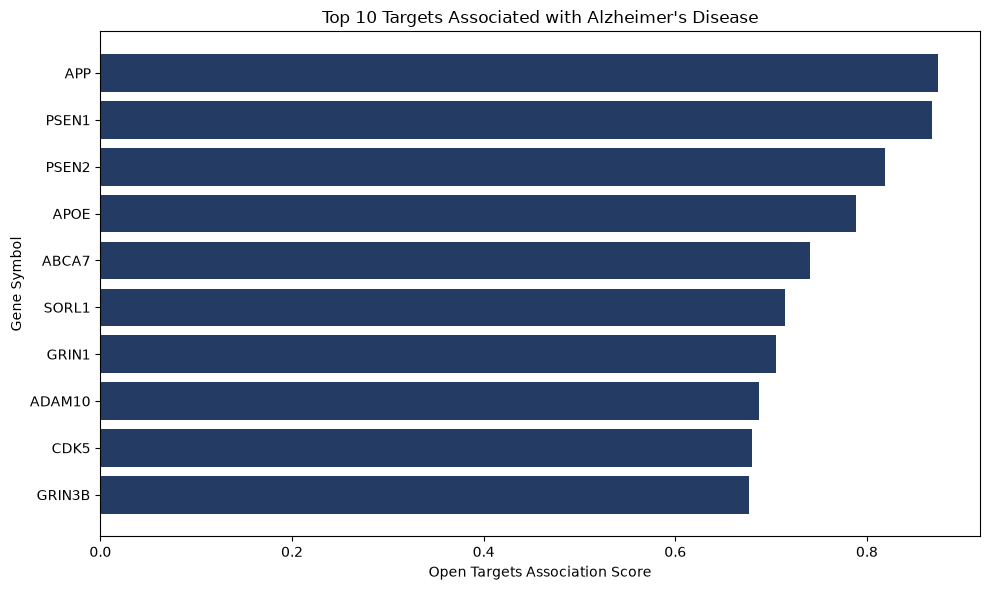

In [50]:

import matplotlib.pyplot as plt

plot_df = target_df.sort_values(
    "association_score", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["gene_symbol"],
    plot_df["association_score"],
    color="#243B64"
)

plt.xlabel("Open Targets Association Score")
plt.ylabel("Gene Symbol")
plt.title("Top 10 Targets Associated with Alzheimer's Disease")
plt.tight_layout()

plt.savefig(
    "alzheimer_target_association.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [51]:

# 1. Find APP in the Open Targets dataset
app_target = target_df[
    target_df["gene_symbol"] == "APP"
].copy()

display(app_target)

# 2. Select APP activity records from ChEMBL
app_activity = activity_clean[
    activity_clean["target_chembl_id"] == "CHEMBL2487"
].copy()

print("Open Targets APP records:", len(app_target))
print("ChEMBL APP activity records:", len(app_activity))

print(
    "Unique compounds:",
    app_activity["molecule_chembl_id"].nunique()
)

display(app_activity.head())


,target_id,gene_symbol,target_name,association_score
0,ENSG00000142192,APP,amyloid beta precursor protein,0.874302


Open Targets APP records: 1
ChEMBL APP activity records: 100
Unique compounds: 55


,molecule_chembl_id,target_chembl_id,assay_chembl_id,standard_type,standard_relation,standard_value,standard_units,pchembl_value,target_organism
0,CHEMBL81260,CHEMBL2487,CHEMBL649398,Ki,=,10.3,nM,7.99,Homo sapiens
1,CHEMBL55380,CHEMBL2487,CHEMBL649398,Ki,=,0.9,nM,9.05,Homo sapiens
2,CHEMBL78410,CHEMBL2487,CHEMBL649398,Ki,>,2000.0,nM,NaN,Homo sapiens
3,CHEMBL81685,CHEMBL2487,CHEMBL649398,Ki,>,1000.0,nM,NaN,Homo sapiens
4,CHEMBL78621,CHEMBL2487,CHEMBL649398,Ki,=,242.0,nM,6.62,Homo sapiens


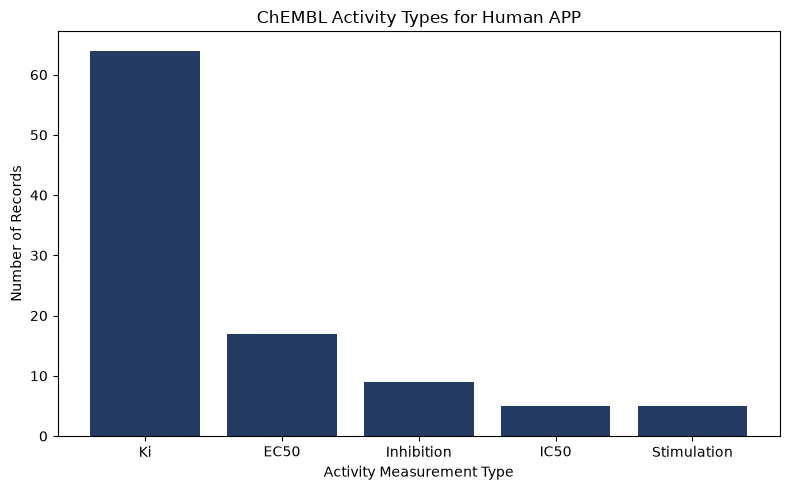

,record_count
standard_type,
Ki,64
EC50,17
Inhibition,9
IC50,5
Stimulation,5


In [52]:

import matplotlib.pyplot as plt

activity_counts = (
    app_activity["standard_type"]
    .value_counts()
)

plt.figure(figsize=(8, 5))

plt.bar(
    activity_counts.index,
    activity_counts.values,
    color="#243B64"
)

plt.xlabel("Activity Measurement Type")
plt.ylabel("Number of Records")
plt.title("ChEMBL Activity Types for Human APP")
plt.tight_layout()

plt.savefig(
    "app_activity_types.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(activity_counts.rename("record_count").to_frame())


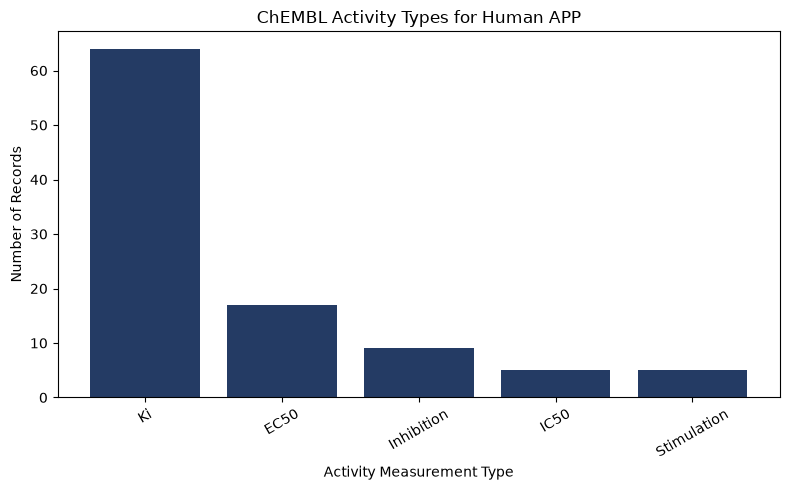

,record_count
standard_type,
Ki,64
EC50,17
Inhibition,9
IC50,5
Stimulation,5


In [53]:
import matplotlib.pyplot as plt

activity_counts = app_activity["standard_type"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(activity_counts.index, activity_counts.values, color="#243B64")
plt.xlabel("Activity Measurement Type")
plt.ylabel("Number of Records")
plt.title("ChEMBL Activity Types for Human APP")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("app_activity_types.png", dpi=300, bbox_inches="tight")
plt.show()

display(activity_counts.rename("record_count").to_frame())

#  Compound-Level Analysis and Research Validation

## Objective
The objective of this analysis is to investigate compounds with reported activity against the human Amyloid Beta Precursor Protein (APP) target using data retrieved from ChEMBL.

## Step 1: Verify Compound Activity Data
In this step, we will check the total number of activity records, count unique compounds, and examine the distribution of activity measurement types.

## Step 2: Filter Ki Measurements
We will select exact Ki measurements reported in nanomolar (nM) units and exclude records with missing values.

## Step 3: Identify Compounds for Further Investigation
We will rank the selected compounds by their recorded Ki values and select five unique compounds for further investigation.

## Research Note
Lower Ki values generally indicate stronger binding affinity when experimental conditions are comparable. However, binding affinity alone does not establish that a compound is an effective treatment for Alzheimer's disease.

In [54]:
# Step 1: Verify APP compound activity data

print("Total APP activity records:", len(app_activity))

print(
    "Unique compounds:",
    app_activity["molecule_chembl_id"].nunique()
)

print("\nActivity types:")
display(
    app_activity["standard_type"]
    .value_counts()
    .rename_axis("activity_type")
    .reset_index(name="record_count")
)

# Select exact Ki measurements in nM
ki_df = activity_clean[
    (activity_clean["standard_type"] == "Ki") &
    (activity_clean["standard_units"] == "nM") &
    (activity_clean["standard_relation"] == "=") &
    (activity_clean["standard_value"].notna())
].copy()

print("\nExact Ki measurements:", len(ki_df))
print(
    "Unique compounds with exact Ki measurements:",
    ki_df["molecule_chembl_id"].nunique()
)

# Select the 5 compounds with the lowest recorded exact Ki values
top_compounds = (
    ki_df.sort_values("standard_value")
    .drop_duplicates(subset="molecule_chembl_id")
    .head(5)
)

display(
    top_compounds[
        [
            "molecule_chembl_id",
            "standard_value",
            "standard_units",
            "pchembl_value",
            "assay_chembl_id"
        ]
    ]
)

Total APP activity records: 100
Unique compounds: 55

Activity types:


,activity_type,record_count
0,Ki,64
1,EC50,17
2,Inhibition,9
3,IC50,5
4,Stimulation,5



Exact Ki measurements: 44
Unique compounds with exact Ki measurements: 33


,molecule_chembl_id,standard_value,standard_units,pchembl_value,assay_chembl_id
34,CHEMBL74704,0.11,nM,9.96,CHEMBL649530
29,CHEMBL76112,0.13,nM,9.89,CHEMBL649530
32,CHEMBL300172,0.14,nM,9.85,CHEMBL649530
43,CHEMBL292910,0.17,nM,9.77,CHEMBL649529
31,CHEMBL305634,0.19,nM,9.72,CHEMBL649530


## Step 2: Retrieve Compound Information from ChEMBL

The ChEMBL database provides information about bioactive compounds, including their identifiers, chemical structures, and molecular properties.

In this step, the selected compounds will be investigated using the ChEMBL API. The retrieved information will be combined with the activity measurements to support further analysis.

The presence of a compound in ChEMBL does not establish that it is an approved drug or an effective treatment for Alzheimer's disease.

In [55]:
import requests
import pandas as pd

compound_details = []

for molecule_id in top_compounds["molecule_chembl_id"].unique():

    url = (
        f"https://www.ebi.ac.uk/chembl/api/data/molecule/"
        f"{molecule_id}.json"
    )

    response = requests.get(url, timeout=30)

    if response.status_code == 200:
        data = response.json()

        compound_details.append({
            "molecule_chembl_id": data.get("molecule_chembl_id"),
            "pref_name": data.get("pref_name"),
            "molecule_type": data.get("molecule_type"),
            "max_phase": data.get("max_phase"),
            "molecular_weight": (
                data.get("molecule_properties") or {}
            ).get("full_mwt")
        })

compound_df = pd.DataFrame(compound_details)

display(compound_df)

,molecule_chembl_id,pref_name,molecule_type,max_phase,molecular_weight
0,CHEMBL74704,NaN,Small molecule,None,481.30
1,CHEMBL76112,NaN,Small molecule,None,481.30
2,CHEMBL300172,CHRYSAMINE G,Small molecule,None,482.45
3,CHEMBL292910,NaN,Small molecule,None,556.35
4,CHEMBL305634,NaN,Small molecule,None,481.30


## Step 3: Integrating Compound and Activity Data

In this step, the compound information retrieved from ChEMBL will be combined with the selected Ki activity measurements. The integrated table will include compound identifiers, available compound names, molecular weights, Ki values, and assay identifiers.

This integration helps organize the experimental activity data and chemical information in a single table. Missing compound names or clinical development information will be retained as missing rather than assumed. The results describe reported experimental measurements and do not establish therapeutic effectiveness against Alzheimer's disease.

In [56]:
# Combine compound details with Ki activity measurements

research_df = top_compounds.merge(
    compound_df,
    on="molecule_chembl_id",
    how="left"
)

# Select useful columns for the research table
research_df = research_df[
    [
        "molecule_chembl_id",
        "pref_name",
        "molecular_weight",
        "standard_value",
        "standard_units",
        "pchembl_value",
        "assay_chembl_id"
    ]
]

research_df = research_df.rename(
    columns={
        "standard_value": "Ki_value_nM",
        "pchembl_value": "pChEMBL"
    }
)

display(research_df)

,molecule_chembl_id,pref_name,molecular_weight,Ki_value_nM,standard_units,pChEMBL,assay_chembl_id
0,CHEMBL74704,NaN,481.30,0.11,nM,9.96,CHEMBL649530
1,CHEMBL76112,NaN,481.30,0.13,nM,9.89,CHEMBL649530
2,CHEMBL300172,CHRYSAMINE G,482.45,0.14,nM,9.85,CHEMBL649530
3,CHEMBL292910,NaN,556.35,0.17,nM,9.77,CHEMBL649529
4,CHEMBL305634,NaN,481.30,0.19,nM,9.72,CHEMBL649530


In [57]:
research_df.to_csv("top_5_app_compounds.csv", index=False)

print("Research table saved successfully!")

Research table saved successfully!
